In [ ]:
import os

import numpy as np

from rect_prune_ood.lib.util.paths import get_top_level_path

results_dir = os.path.join(get_top_level_path(), 'results')
imagenet_c_results_dir = os.path.join(results_dir, 'imagenet', 'baseline', 'imagenet_c')
ablation_study_results_dir = os.path.join(results_dir, 'ablation_study_pertubation')
os.makedirs(ablation_study_results_dir, exist_ok=True)

imagenet_c_pertubations = [
	'gaussian_noise',
	'saturate',
	'brightness',
	'pixelate',
	'snow',
	'motion_blur',
	'elastic_transform',
	'fog',
	'zoom_blur',
	'shot_noise',
	'contrast',
	'defocus_blur',
	'frost',
	'impulse_noise',
	'jpeg_compression',
	'glass_blur',
]

imagenet_c_pertubations_all = [
	'brightness',
	'defocus_blur',
	'fog',
	'gaussian_blur',
	'glass_blur',
	'jpeg_compression',
	'pixelate',
	'shot_noise',
	'spatter',
	'zoom_blur',
	'contrast',
	'elastic_transform',
	'frost',
	'gaussian_noise',
	'impulse_noise',
	'motion_blur',
	'saturate',
	'snow',
	'speckle_noise',
]

In [9]:
from torch import Tensor
from torch.nn import Module


class APESP(Module):
	def __init__(self, mask) -> None:
		# super(LayerScaler, self).__init__()
		super(APESP, self).__init__()
		self.mask = mask

	def forward(self, x: Tensor) -> Tensor:
		x = self.apes_p(x)
		return x

	def apes_p(self, x):
		assert x.dim() == 4
		_, c, _, _ = x.shape
		assert self.mask.shape[0] == c

		x = x * self.mask

		return x

In [2]:
imagenet_c_activations = np.load(
	os.path.join(imagenet_c_results_dir, 'imagenet_c_activations_severity_5.npy')
)
imagenet_activations = np.load(
	os.path.join(results_dir, 'imagenet', 'baseline', 'imagenet_activations.npy')
)
print(imagenet_c_activations.shape)
print(imagenet_activations.shape)
imagenet_activations = np.transpose(imagenet_activations)
print(imagenet_activations.shape)

(19, 2048, 50000)
(50000, 2048)
(2048, 50000)


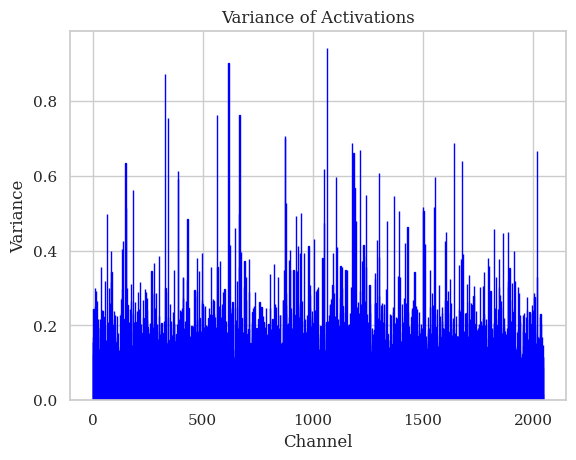

In [ ]:
import matplotlib.pyplot as plt

activations = imagenet_c_activations[0]

variance = np.var(activations, axis=1)


plt.rcParams.update({'text.usetex': False, 'font.family': 'serif'})

# Create a bar graph
plt.bar(range(len(variance)), variance, edgecolor='blue')
plt.xlabel('Channel')
plt.ylabel('Variance')

# Add a title and show the plot
plt.title('Variance of Activations')

# save as pdf
plt.savefig(os.path.join(results_dir, 'plots', 'variance_of_activations.pdf'))

plt.show()

In [21]:
import torch
from lightning import Trainer

from rect_prune_ood.lib.experiments.backbones import get_resnet50
from rect_prune_ood.lib.experiments.feature_extractor import FeatureExtractor
from rect_prune_ood.lib.experiments.pipeline import Pipeline
from rect_prune_ood.lib.util.data_loader import get_data_loader

for i in range(len(imagenet_c_pertubations_all)):
	activations = imagenet_c_activations[i]

	variance = np.var(activations, axis=1)
	variance = torch.tensor(variance)

	percentile = np.percentile(variance, 70)

	mask = torch.where(variance <= percentile, 1, 0)
	mask = mask.view(variance.shape[0], 1, 1).cuda()

	#################
	### ImageNet ####
	#################

	feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')

	fc_layer = feature_extractor.get_fc_layer()

	pipeline = Pipeline(
		feature_extractor, 'baseline', fc_layer, caputure_activations=False
	)
	pipeline.method_list = [APESP(mask)]

	dataloader, _ = get_data_loader('imagenet', batch_size=16)

	# Trainer
	trainer = Trainer(logger=None)
	trainer.test(pipeline, dataloader)

	results = pipeline.results
	np.save(
		os.path.join(
			ablation_study_results_dir,
			f'as_{imagenet_c_pertubations_all[i]}_imagenet.npy',
		),
		results,
	)

	####################
	### OpenImage-O ####
	####################

	feature_extractor = FeatureExtractor(get_resnet50(), 'avgpool')

	fc_layer = feature_extractor.get_fc_layer()

	pipeline = Pipeline(
		feature_extractor, 'baseline', fc_layer, caputure_activations=False
	)
	pipeline.method_list = [APESP(mask)]

	dataloader, _ = get_data_loader('openimage-o', batch_size=16)

	# Trainer
	trainer = Trainer(logger=None)
	trainer.test(pipeline, dataloader)

	results = pipeline.results

	np.save(
		os.path.join(
			ablation_study_results_dir,
			f'as_{imagenet_c_pertubations_all[i]}_openimage-o.npy',
		),
		results,
	)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

... (66 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Testing: |          | 0/? [00:00<?, ?it/s]

In [ ]:
import csv
import os

from rect_prune_ood.lib.eval.metrics import cal_metric

all_results = []

for i in range(len(imagenet_c_pertubations_all)):
	imagenet_scores = np.load(
		os.path.join(
			ablation_study_results_dir,
			f'as_{imagenet_c_pertubations_all[i]}_imagenet.npy',
		),
		allow_pickle=True,
	).item()['energy_score']
	openimage_o_scores = np.load(
		os.path.join(
			ablation_study_results_dir,
			f'as_{imagenet_c_pertubations_all[i]}_openimage-o.npy',
		),
		allow_pickle=True,
	).item()['energy_score']

	results = cal_metric(imagenet_scores, openimage_o_scores)
	results['perturbation'] = imagenet_c_pertubations_all[i]

	all_results.append(results)

csv_filename = os.path.join(
	ablation_study_results_dir, 'as_single_perturbation_results.csv'
)

with open(csv_filename, mode='w', newline='') as file:
	writer = csv.DictWriter(file, fieldnames=['perturbation', 'FPR', 'AUROC'])
	writer.writeheader()
	for results in all_results:
		writer.writerow(
			{
				'perturbation': results['perturbation'],
				'FPR': results['FPR'],
				'AUROC': results['AUROC'],
			}
		)

# Read data from the CSV file
results = []
with open(csv_filename, mode='r', newline='') as file:
	reader = csv.DictReader(file)
	for row in reader:
		# Convert numerical values to float for sorting
		row['FPR'] = float(row['FPR'])
		row['AUROC'] = float(row['AUROC'])
		results.append(row)

# Sort by AUROC in ascending order
sorted_results = sorted(results, key=lambda x: x['AUROC'], reverse=True)

# Print the sorted results
for row in sorted_results:
	print(row)

{'perturbation': 'spatter', 'FPR': 0.5508166969147006, 'AUROC': 0.8553681198956442}
{'perturbation': 'elastic_transform', 'FPR': 0.5282441016333939, 'AUROC': 0.8452922515880218}
{'perturbation': 'saturate', 'FPR': 0.6004423774954628, 'AUROC': 0.833565834845735}
{'perturbation': 'gaussian_blur', 'FPR': 0.6788793103448276, 'AUROC': 0.8217950056715064}
{'perturbation': 'defocus_blur', 'FPR': 0.7088248638838476, 'AUROC': 0.8153395638611616}
{'perturbation': 'zoom_blur', 'FPR': 0.6491039019963702, 'AUROC': 0.8150708773820327}
{'perturbation': 'brightness', 'FPR': 0.6388951905626135, 'AUROC': 0.8141784046052631}
{'perturbation': 'contrast', 'FPR': 0.7714382940108893, 'AUROC': 0.8129045672640653}
{'perturbation': 'shot_noise', 'FPR': 0.7696801270417423, 'AUROC': 0.7985962108666061}
{'perturbation': 'gaussian_noise', 'FPR': 0.771608439201452, 'AUROC': 0.7924243131805806}
{'perturbation': 'motion_blur', 'FPR': 0.7680921052631579, 'AUROC': 0.7896854854809436}
{'perturbation': 'glass_blur', 'FPR'